# 07 펌프 센서 간 상관관계 히트맵

1. 원본과 최종 전처리 결과 연결
2. 센서 49개의 정상·회복 상태별 상관과 보간 영향
3. 참고용 원본 센서 52개 상관 히트맵

원본에 실제로 관측된 센서 쌍과 선형보간 이후의 결과를 같은 상태별로 비교합니다. 기존 원본 52개 히트맵은 아래 참고 절에서 다시 생성할 수 있습니다.

### 확인한 결과

- 정상과 회복 모두 같은 방향으로 절대 Pearson 상관이 0.95 이상인 센서 쌍은 7개입니다. sensor_19·20·21은 대표 센서로 줄여볼 수 있는 후보입니다.
- sensor_29–sensor_35 상관은 정상 +0.290에서 회복 −0.916으로 바뀌었습니다.
- 회복 중 sensor_00–sensor_05 상관은 원본 관측 +0.664에서 선형보간 후 −0.354로 바뀌었습니다. 원본에서는 동시 관측 4,283행, 보간 후에는 14,477행을 사용했습니다.

## 1. 원본과 최종 전처리 결과 연결

원본에서 고장·회복 상태와 관측 여부를 읽고, 05 노트북이 생성한 최종 CSV에서 선형보간값과 라벨을 읽습니다. 같은 시각의 값만 비교하며, 분석 대상은 최종 데이터의 센서 49개입니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src/pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("저장소 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(project_root))
from src.plot_style import save_png, use_portable_style
from src.pump_missingness_audit import MINUTE, default_source, read_csv_exact, read_sensor_data

# 모든 OS에서 같은 글꼴과 같은 PNG가 나오도록 설정합니다.
use_portable_style()

raw = read_sensor_data(default_source())
final_path = project_root / "data/processed/sensor_linear_interpolation_labeled.csv"
if not final_path.is_file():
    raise FileNotFoundError("먼저 05_pump_binary_labels.ipynb를 실행해 최종 CSV를 만드세요.")
final = read_csv_exact(final_path)
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
final_timestamps = pd.to_datetime(final["timestamp"], errors="raise")
if not timestamps.equals(final_timestamps) or timestamps.isna().any() or not timestamps.diff().iloc[1:].eq(MINUTE).all():
    raise ValueError("원본과 최종 CSV의 1분 간격 타임스탬프가 같은지 확인하세요.")

excluded = {"sensor_15", "sensor_50", "sensor_51"}
sensor_columns = [column for column in final if column.startswith("sensor_")]
assert set(sensor_columns) == {f"sensor_{i:02d}" for i in range(52)} - excluded
raw_sensors = raw[sensor_columns].astype("float64")
filled_sensors = final[sensor_columns].astype("float64")
status = raw["machine_status"]
label_map = {"NORMAL": "normal", "BROKEN": "abnormal", "RECOVERING": "abnormal"}
assert status.map(label_map).rename("label").equals(final["label"])
observed = raw_sensors.notna().to_numpy()
assert np.isfinite(filled_sensors.to_numpy()).all()
np.testing.assert_array_equal(raw_sensors.to_numpy()[observed], filled_sensors.to_numpy()[observed])

figure_dir = project_root / "figures/pump_eda"
figure_dir.mkdir(parents=True, exist_ok=True)
print(f"{timestamps.iloc[0]} ~ {timestamps.iloc[-1]} · {len(final):,}행 · 센서 {len(sensor_columns)}개")
print(f"원래 결측 {int((~observed).sum()):,}셀 · 최종 센서 결측 0셀")

2018-04-01 00:00:00 ~ 2018-08-31 23:59:00 · 220,320행 · 센서 49개
원래 결측 31,854셀 · 최종 센서 결측 0셀


## 2. 센서 간 상관관계

원본 전체, 정상, 회복의 Pearson 상관계수를 나란히 비교합니다. 원본은 각 센서 쌍의 두 값이 모두 관측된 행으로 계산합니다. 보간 전후를 전체·정상·회복별로 비교해 보간에 민감한 쌍을 확인합니다. 두 상태에서 모두 강하게 함께 움직이는 쌍은 중복 후보입니다. 상태에 따라 상관이 크게 달라지는 쌍은 따로 살펴봅니다. 상관계수는 예측 성능을 직접 보여주지 않으므로 최종 센서 선택에는 사건별 패턴과 모델 검증을 함께 사용합니다.

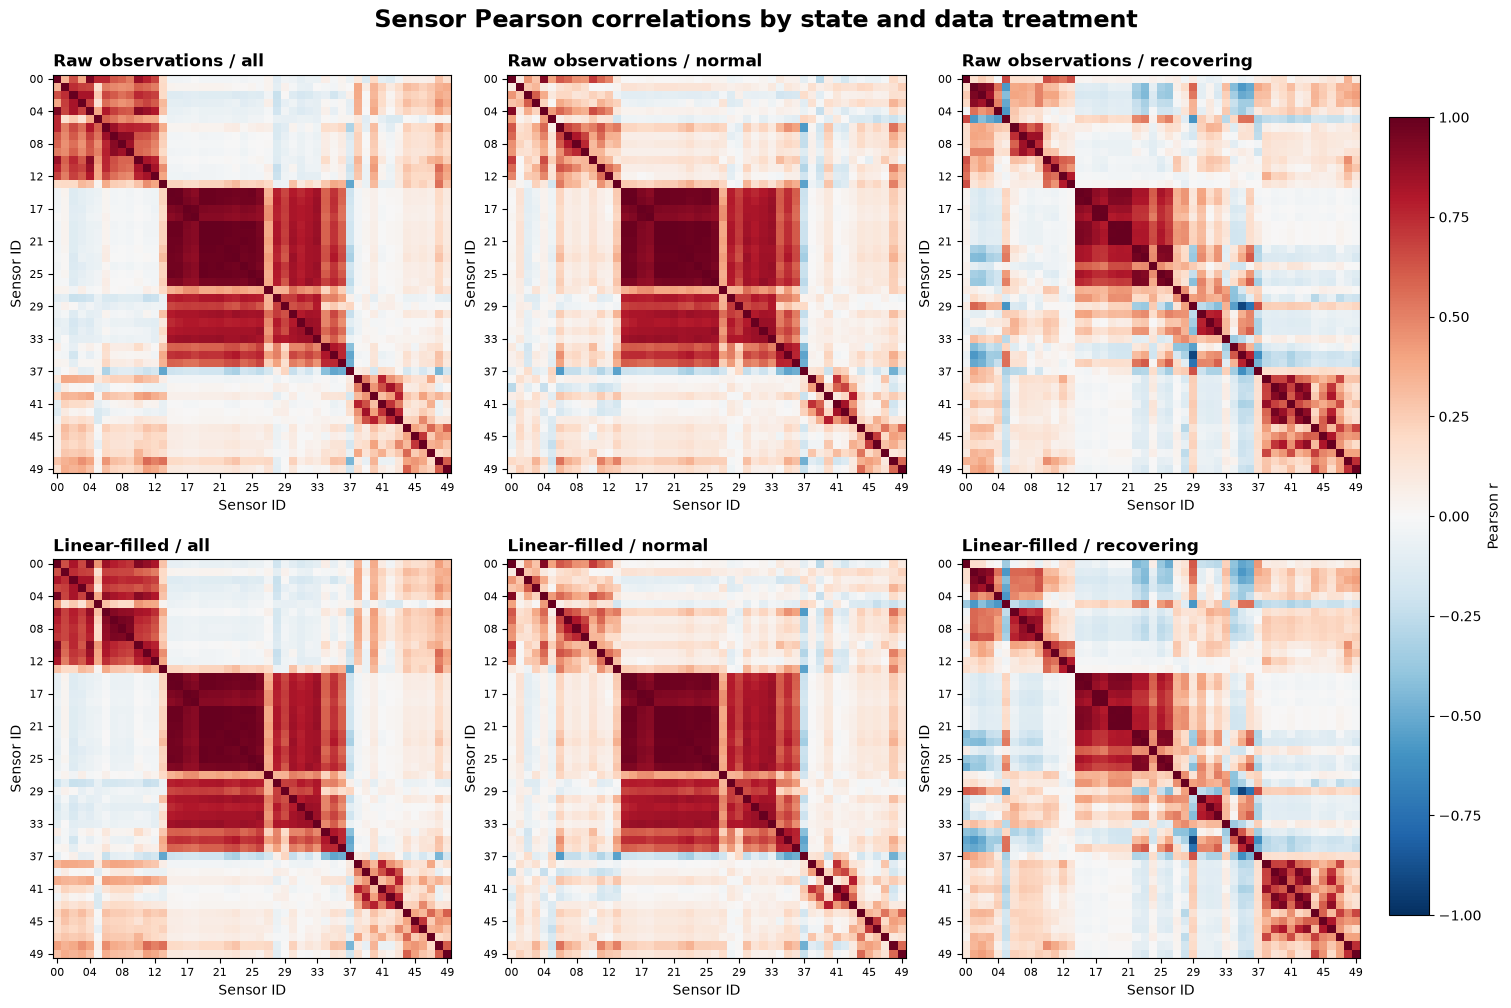

In [ ]:
normal_readings = raw_sensors.loc[status.eq("NORMAL")]
recovering_readings = raw_sensors.loc[status.eq("RECOVERING")]
correlation_matrices = {
    "Raw observations / all": raw_sensors.corr(min_periods=30),
    "Raw observations / normal": normal_readings.corr(min_periods=30),
    "Raw observations / recovering": recovering_readings.corr(min_periods=30),
    "Linear-filled / all": filled_sensors.corr(min_periods=30),
    "Linear-filled / normal": filled_sensors.loc[status.eq("NORMAL")].corr(min_periods=30),
    "Linear-filled / recovering": filled_sensors.loc[status.eq("RECOVERING")].corr(min_periods=30),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")
fig.suptitle("Sensor Pearson correlations by state and data treatment", fontsize=17, fontweight="bold")
tick_positions = np.unique(np.r_[np.arange(0, len(sensor_columns), 4), len(sensor_columns) - 1])
tick_labels = [sensor_columns[position].removeprefix("sensor_") for position in tick_positions]
for axis, (title, matrix) in zip(axes.flat, correlation_matrices.items()):
    image = axis.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="none")
    axis.set_title(title, loc="left", fontweight="bold", fontsize=12)
    axis.set_xticks(tick_positions, tick_labels, fontsize=8)
    axis.set_yticks(tick_positions, tick_labels, fontsize=8)
    axis.set_xlabel("Sensor ID")
    axis.set_ylabel("Sensor ID")
fig.colorbar(image, ax=axes, label="Pearson r", shrink=.84, pad=.02)
save_png(fig, figure_dir / "sensor_correlation_heatmaps.png", dpi=150, facecolor="white")
display(fig)
plt.close(fig)

In [ ]:
row_ids, col_ids = np.triu_indices(len(sensor_columns), k=1)
names = np.asarray(sensor_columns)
correlation_pairs = pd.DataFrame({"센서 A": names[row_ids], "센서 B": names[col_ids]})
for label, matrix in zip(
    ("원본 전체", "정상", "회복", "보간 전체", "보간 정상", "보간 회복"), correlation_matrices.values()
):
    correlation_pairs[label] = matrix.to_numpy()[row_ids, col_ids]

for label, readings in (("정상", normal_readings), ("회복", recovering_readings)):
    observed = readings.notna().to_numpy(dtype=np.float64)
    pair_counts = observed.T @ observed
    correlation_pairs[f"{label} 동시 관측 수"] = pair_counts[row_ids, col_ids].astype(int)

correlation_pairs["상태 간 차이"] = (correlation_pairs["정상"] - correlation_pairs["회복"]).abs()
for raw_label, filled_label, difference_label in (
    ("원본 전체", "보간 전체", "보간 전후 차이"),
    ("정상", "보간 정상", "정상 보간 전후 차이"),
    ("회복", "보간 회복", "회복 보간 전후 차이"),
):
    correlation_pairs[difference_label] = (correlation_pairs[raw_label] - correlation_pairs[filled_label]).abs()
correlation_pairs["회복 보간 후 행 수"] = int(status.eq("RECOVERING").sum())
both_states_high = (
    correlation_pairs[["정상", "회복"]].abs().min(axis=1).ge(.95)
    & correlation_pairs["정상"].mul(correlation_pairs["회복"]).gt(0)
)
pair_columns = ["센서 A", "센서 B", "원본 전체", "정상", "회복",
                "정상 동시 관측 수", "회복 동시 관측 수", "상태 간 차이"]
redundant_pairs = correlation_pairs.loc[both_states_high].sort_values(
    "원본 전체", key=lambda values: values.abs(), ascending=False
).head(8)
state_sensitive_pairs = correlation_pairs.nlargest(8, "상태 간 차이")
fill_sensitive_pairs = correlation_pairs.nlargest(5, "보간 전후 차이")
fill_recovery_sensitive_pairs = correlation_pairs.nlargest(8, "회복 보간 전후 차이")
recovery_columns = ["센서 A", "센서 B", "회복", "보간 회복", "회복 보간 전후 차이",
                    "회복 동시 관측 수", "회복 보간 후 행 수"]

print(f"두 상태 모두 |r| ≥ 0.95이고 방향이 같은 쌍 {int(both_states_high.sum())}개 (검토 기준)")
display(redundant_pairs[pair_columns].round(3).reset_index(drop=True))
print("정상과 회복의 상관 차이가 큰 쌍")
display(state_sensitive_pairs[pair_columns].round(3).reset_index(drop=True))
print("전체 상관이 보간에 가장 민감한 쌍")
display(fill_sensitive_pairs[["센서 A", "센서 B", "원본 전체", "보간 전체", "보간 전후 차이"]].round(3).reset_index(drop=True))
print("회복 상관이 보간에 가장 민감한 쌍")
display(fill_recovery_sensitive_pairs[recovery_columns].round(3).reset_index(drop=True))

두 상태 모두 |r| ≥ 0.95이고 방향이 같은 쌍 7개 (검토 기준)


,센서 A,센서 B,원본 전체,정상,회복,정상 동시 관측 수,회복 동시 관측 수,상태 간 차이
0,sensor_19,sensor_20,0.998,0.998,0.990,205820,14477,0.008
1,sensor_20,sensor_21,0.997,0.997,0.995,205820,14477,0.002
2,sensor_19,sensor_21,0.996,0.996,0.993,205820,14477,0.003
3,sensor_14,sensor_16,0.990,0.990,0.978,205805,14477,0.012
4,sensor_22,sensor_23,0.987,0.987,0.968,205795,14477,0.019
5,sensor_17,sensor_18,0.983,0.984,0.990,205790,14477,0.006
6,sensor_25,sensor_26,0.971,0.971,0.954,205796,14477,0.016


정상과 회복의 상관 차이가 큰 쌍


,센서 A,센서 B,원본 전체,정상,회복,정상 동시 관측 수,회복 동시 관측 수,상태 간 차이
0,sensor_29,sensor_35,0.260,0.290,-0.916,205764,14477,1.206
1,sensor_29,sensor_32,0.650,0.686,-0.423,205712,14477,1.109
2,sensor_26,sensor_29,0.620,0.636,-0.414,205760,14477,1.051
3,sensor_29,sensor_31,0.673,0.702,-0.334,205764,14477,1.036
4,sensor_25,sensor_33,0.848,0.857,-0.152,205800,14477,1.009
5,sensor_22,sensor_29,0.645,0.658,-0.346,205739,14477,1.005
6,sensor_23,sensor_29,0.620,0.634,-0.370,205764,14477,1.004
7,sensor_04,sensor_05,0.386,0.429,-0.576,205822,14472,1.004


전체 상관이 보간에 가장 민감한 쌍


,센서 A,센서 B,원본 전체,보간 전체,보간 전후 차이
0,sensor_05,sensor_07,0.541,0.227,0.314
1,sensor_05,sensor_09,0.504,0.192,0.312
2,sensor_00,sensor_05,0.757,0.445,0.311
3,sensor_00,sensor_01,0.339,0.645,0.306
4,sensor_05,sensor_06,0.594,0.300,0.294


회복 상관이 보간에 가장 민감한 쌍


,센서 A,센서 B,회복,보간 회복,회복 보간 전후 차이,회복 동시 관측 수,회복 보간 후 행 수
0,sensor_00,sensor_05,0.664,-0.354,1.018,4283,14477
1,sensor_00,sensor_11,0.588,-0.016,0.605,4283,14477
2,sensor_00,sensor_10,0.646,0.069,0.578,4283,14477
3,sensor_00,sensor_26,0.048,-0.497,0.545,4283,14477
4,sensor_00,sensor_29,0.082,0.612,0.530,4283,14477
5,sensor_05,sensor_09,0.168,-0.328,0.495,9896,14477
6,sensor_05,sensor_06,0.248,-0.246,0.494,9693,14477
7,sensor_05,sensor_07,0.147,-0.346,0.493,9040,14477


### 상관관계 해석

원본 관측에서 sensor_19와 sensor_20은 정상 0.998, 회복 0.990으로 두 상태에서 강한 양의 상관을 유지합니다. sensor_19와 sensor_24는 정상 0.988에서 회복 0.655로 낮아져 회복 중 별도 정보가 있을 수 있습니다. sensor_00과 sensor_05는 회복 중 원본 0.664에서 보간 후 -0.354로 부호가 바뀝니다. 보간한 구간이 많은 회복의 상관계수는 원본과 비교해 해석합니다. 실제 센서 제거는 사건별 고장 직전 패턴과 후속 모델 비교에서 확인합니다. [Pearson 상관계수 정의](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)

## 3. 참고용 원본 센서 52개 상관 히트맵

이 절은 분석 초기에 작성한 원본 전체 센서 히트맵을 재현합니다. 아래에서 대상 목록을 원본 52개로 바꿉니다.

In [ ]:
sensor_columns = sorted(column for column in raw if column.startswith("sensor_"))

### 센서 쌍별 상관계수 계산

피어슨 상관계수는 두 센서에 값이 모두 있는 같은 시각의 행으로 계산합니다. 결측을 채우지 않기 때문에 센서 쌍마다 사용한 행 수가 다를 수 있습니다. `sensor_15`처럼 관측값이 없거나 비교할 값에 변동이 없으면 계수는 비어 있습니다. 아래 표는 절댓값이 큰 상관계수 10쌍과 계산에 사용한 행 수를 보여줍니다.

In [ ]:
readings = raw[sensor_columns]
correlation = readings.corr(method="pearson", min_periods=2)

# 두 센서가 모두 관측된 행의 수를 센서 쌍별로 셉니다.
observed = readings.notna().to_numpy(dtype="float64")
overlap = (observed.T @ observed).astype("int64")
pair_count = pd.DataFrame(overlap, index=sensor_columns, columns=sensor_columns)

# 대각선과 대칭으로 중복되는 쌍을 한 번씩만 표시합니다.
row, col = np.triu_indices(len(sensor_columns), k=1)
pairs = pd.DataFrame({
    "센서 A": correlation.index[row],
    "센서 B": correlation.columns[col],
    "피어슨 r": correlation.to_numpy()[row, col],
    "동시 관측 행 수": overlap[row, col],
}).dropna(subset=["피어슨 r"])
strongest = pairs.loc[pairs["피어슨 r"].abs().nlargest(10).index]
display(strongest.reset_index(drop=True).round({"피어슨 r": 4}))
undefined_sensors = correlation.index[correlation.isna().all(axis=1)]
print("상관계수를 계산할 수 없는 센서:", ", ".join(undefined_sensors) or "없음")

,센서 A,센서 B,피어슨 r,동시 관측 행 수
0,sensor_19,sensor_20,0.9982,220304
1,sensor_20,sensor_21,0.9971,220304
2,sensor_19,sensor_21,0.9960,220304
3,sensor_14,sensor_16,0.9904,220289
4,sensor_19,sensor_22,0.9882,220279
5,sensor_22,sensor_23,0.9869,220279
6,sensor_20,sensor_22,0.9865,220279
7,sensor_19,sensor_24,0.9856,220304
8,sensor_21,sensor_24,0.9849,220304
9,sensor_19,sensor_25,0.9848,220284


상관계수를 계산할 수 없는 센서: sensor_15


### 히트맵 확인 및 PNG 저장

파란색은 음의 상관, 붉은색은 양의 상관, 회색은 계산할 수 없는 셀입니다. 상관계수는 같은 시각의 선형 관계를 나타냅니다. 저장 경로는 `figures/sensor_correlations/pearson_correlation.png`입니다.

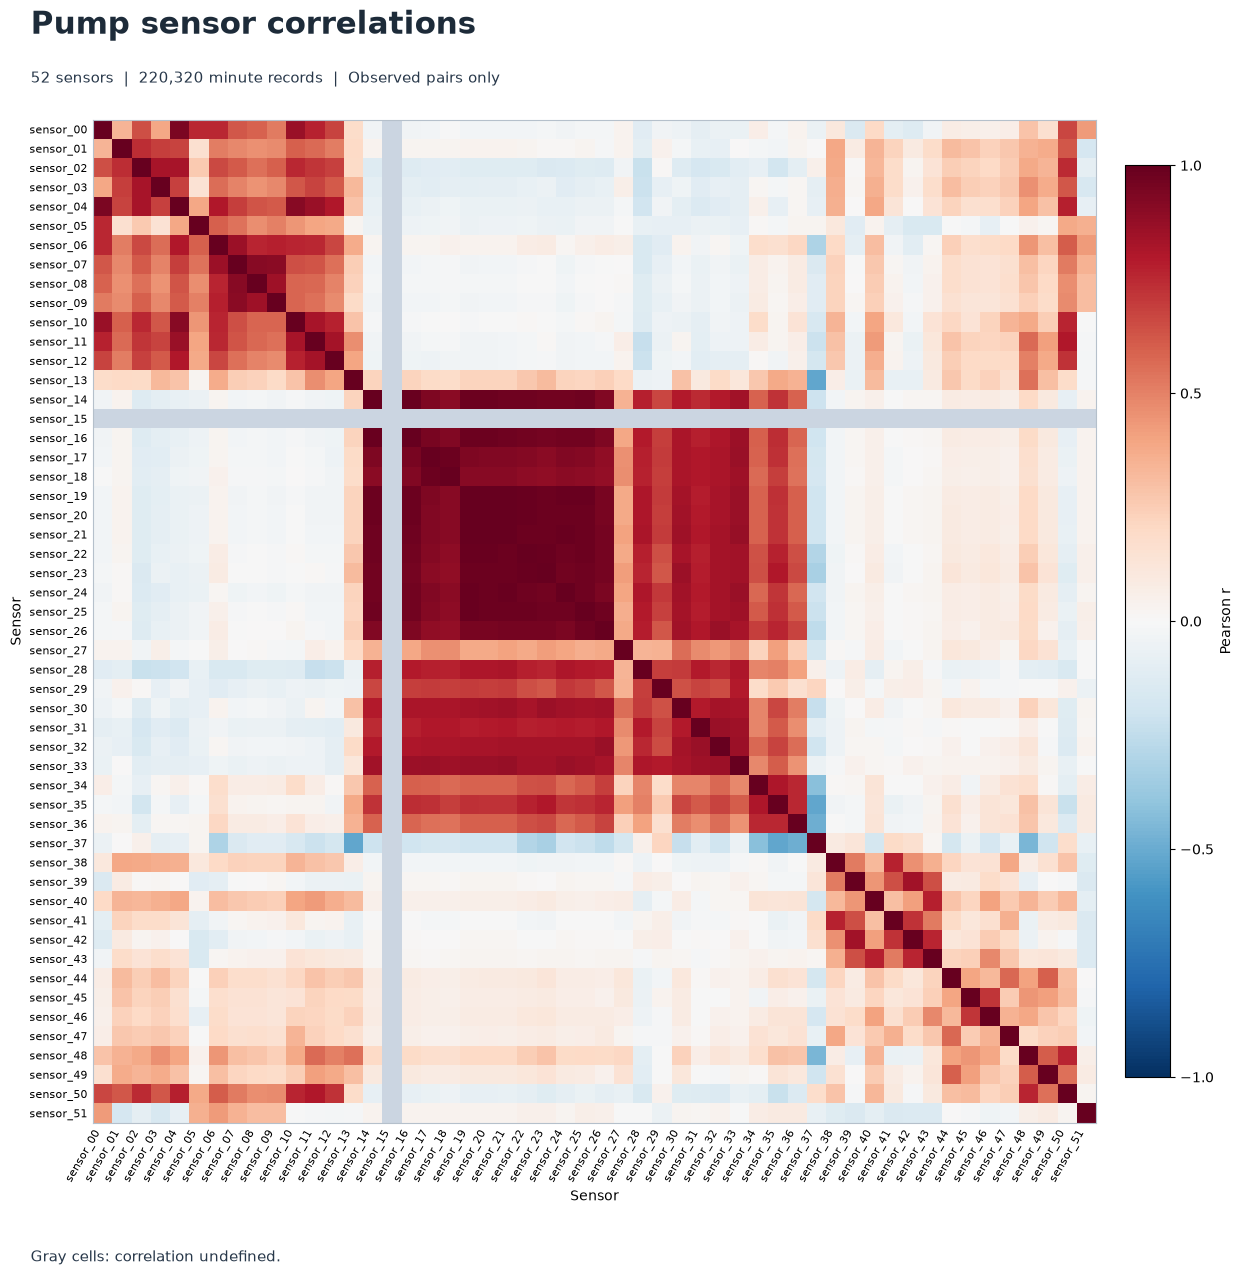

저장: figures/sensor_correlations/pearson_correlation.png


In [ ]:
output_dir = project_root / "figures/sensor_correlations"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "pearson_correlation.png"

cmap = plt.get_cmap("RdBu_r").with_extremes(bad="#cbd5e1")
fig, ax = plt.subplots(figsize=(14.8, 13.2))
fig.subplots_adjust(left=.12, right=.89, bottom=.13, top=.89)
image = ax.imshow(correlation.to_numpy(), cmap=cmap, vmin=-1, vmax=1, interpolation="nearest")
positions = np.arange(len(sensor_columns))
ax.set_xticks(positions, sensor_columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(positions, sensor_columns, fontsize=8)
ax.tick_params(length=0, pad=4)
ax.set_xlabel("Sensor")
ax.set_ylabel("Sensor")
for spine in ax.spines.values():
    spine.set_color("#b5c0cb")
bar = fig.colorbar(image, ax=ax, fraction=.04, pad=.025, ticks=[-1, -.5, 0, .5, 1])
bar.set_label("Pearson r")
fig.text(.12, .955, "Pump sensor correlations", fontsize=22, fontweight="bold", color="#1d2b39")
fig.text(
    .12, .918,
    f"{len(sensor_columns)} sensors  |  {len(raw):,} minute records  |  Observed pairs only",
    fontsize=11, color="#28384a",
)
fig.text(.12, .025, "Gray cells: correlation undefined.", fontsize=11, color="#28384a")
save_png(fig, output_path, dpi=150, facecolor="white")
plt.show()
print(f"저장: {output_path.relative_to(project_root).as_posix()}")